# Deteksi Hoaks pada Tweet Berbahasa Indonesia (IDNHoaxCorpus)

**Kelompok 6** — Klasifikasi teks 3 kelas: `hoax`, `valid`, `tidak_jelas`

# 1. Business Problem Understanding

## Latar Belakang

## Outline
1. Business Problem Understanding <br>
2. Data Understanding <br>
3. Data Preprocessing <br>
4. Modeling <br>
5. Conclusion <br>
6. Recommendation <br>

Media sosial tidak hanya dipakai untuk bersosialisasi, tetapi juga menjadi jalur cepat penyebaran informasi palsu (hoaks). Twitter/X menjadi salah satu kanal utama karena unggahan dapat menyebar luas dalam hitungan menit tanpa proses penyuntingan atau verifikasi. Di Indonesia, masalah ini semakin serius karena jumlah pengguna media sosial yang besar dan keberagaman masyarakatnya; Syaifuddiin dkk. (2023) mengutip data Kementerian Kominfo yang mencatat sekitar 800.000 situs penyebar hoaks di Indonesia.

Hoaks paling sering muncul pada topik kesehatan dan kejadian penting, misalnya klaim bahwa vaksin menyebabkan autis, air garam bisa menjadi sumber listrik rumah tangga, atau ramuan tertentu menyembuhkan penyakit berat. Informasi seperti ini dibungkus dengan bahasa yang meyakinkan dan ajakan untuk "share ke grup", sehingga cepat dipercaya. Tim cek fakta yang memverifikasi secara manual tidak mampu mengikuti volume unggahan baru yang terus bertambah, sehingga dibutuhkan sistem yang dapat menyaring tweet secara otomatis sebelum diverifikasi oleh manusia.

source : Syaifuddiin, Arifin, Desriyanti, Rosyidin, Pratama & Selamat (2023), *Hoax Identification of Indonesian Tweeters Using Ensemble Classifier*, Journal of Information Systems and Telecommunication, 11(2), 94–101.

## Problem Statement

Tim cek fakta menghadapi ribuan tweet setiap hari dan tidak mungkin memverifikasi semuanya satu per satu. Tanpa penyaringan awal, tweet hoaks dapat lolos dan tersebar luas, sementara tenaga verifikasi habis untuk tweet yang sebenarnya valid. Selain itu, tidak semua tweet dapat langsung dinilai benar atau salah: sebagian isinya ambigu atau tidak cukup informasi (label `?` / `tidak_jelas`), dan tweet seperti ini perlu ditangani berbeda dari hoaks yang jelas.

Maka dari itu, dibutuhkan sebuah sistem yang dapat **mengklasifikasikan tweet berbahasa Indonesia ke dalam kategori hoax, valid, atau tidak_jelas hanya berdasarkan teks tweet**, sehingga tim cek fakta dapat memprioritaskan tweet yang paling perlu diperiksa.

## Goals

Berdasarkan problem statement di atas, tujuan dari project ini adalah:
1. Membangun model klasifikasi teks yang dapat memprediksi label `hoax`, `valid`, atau `tidak_jelas` dari isi tweet.
2. Membandingkan beberapa pendekatan representasi teks dan algoritma (baseline kelas mayoritas, TF-IDF, embedding sederhana/SVD, FastText, dan model ensemble) secara adil pada split data yang sama.
3. Mengetahui kata atau frasa yang paling membedakan tiap kelas, sehingga hasil model dapat diinterpretasikan oleh tim cek fakta.

## Analytic Approach

Untuk mencapai tujuan tersebut, kami membangun model **klasifikasi multikelas (3 kelas)** dengan fitur yang diambil **hanya dari kolom `tweet`**. Teks dibersihkan dengan aturan yang terdokumentasi (URL, mention, angka, emoji, kata gaul, dan negasi), lalu diubah menjadi vektor menggunakan TF-IDF, SVD (Latent Semantic Analysis), dan FastText. Beberapa algoritma diuji dengan *Stratified 5-Fold Cross Validation* pada data latih, kemudian model terbaik di-*tuning* dan dievaluasi sekali pada data uji.

Kolom `topik`, `keyword`, `gambar`, dan `url` **tidak dipakai sebagai fitur** karena berpotensi membocorkan label (dibuktikan pada bagian EDA). Kolom tersebut hanya dipakai untuk analisis.

Data source : IDNHoaxCorpus / IndoHoaxCorpus, Mendeley Data — https://data.mendeley.com/datasets/kc3mvspnp4/1

## Metric Evaluation

Distribusi kelas tidak seimbang (`hoax` jauh lebih banyak), sehingga **akurasi saja menyesatkan**: model yang selalu menebak `hoax` sudah mendapat akurasi sekitar 65% tanpa belajar apa pun. Karena itu digunakan metrik berikut:

**1. F1-score Makro (metrik utama)**
- **Fungsi:** Mengukur keseimbangan precision dan recall untuk setiap kelas, lalu dirata-rata tanpa bobot.
- **Karakteristik:** Setiap kelas dihitung sama penting, sehingga kelas kecil (`valid` dan `tidak_jelas`) tidak tertutup oleh kelas mayoritas.
- **Perhitungan:** $F1_{makro} = \frac{1}{K}\sum_{k=1}^{K} \frac{2 \cdot P_k \cdot R_k}{P_k + R_k}$

**2. Precision, Recall, dan F1 per kelas**
- **Fungsi:** Menunjukkan performa model di masing-masing kelas.
- **Karakteristik:** *Recall hoax* rendah berarti banyak hoaks lolos tidak terdeteksi; *precision hoax* rendah berarti banyak tweet valid dituduh hoaks. Fokus analisis ada pada kelas `valid` dan `tidak_jelas`.

**3. Confusion Matrix**
- **Fungsi:** Menunjukkan kelas mana yang paling sering tertukar.
- **Karakteristik:** Menggantikan plot *actual vs prediction* pada kasus regresi.

**4. Akurasi (pendamping)**
- Tetap dilaporkan sebagai pembanding, tetapi tidak dijadikan dasar pemilihan model.

# 2. Data Understanding

| Field   | Description                                                                 | Dipakai sebagai fitur? |
|---------|-----------------------------------------------------------------------------|------------------------|
| topik   | Topik atau tema tweet (misal: Vaksin, Garam, Kopi).                          | Tidak (hanya EDA)      |
| keyword | Kata kunci yang dipakai untuk mencari tweet (misal: "Vaksin penyebab autis"). | Tidak (bocor label)    |
| tweet   | Isi teks tweet hasil pencarian.                                              | **Ya — fitur utama**   |
| gambar  | URL gambar yang disertakan dalam tweet (jika ada).                           | Tidak                  |
| url     | URL tweet.                                                                   | Tidak                  |
| label   | Label tweet: `hoax`, `valid`, atau `?` (tidak jelas).                        | **Target**             |

In [2]:
# !pip install pandas numpy matplotlib seaborn scikit-learn xgboost lightgbm gensim Sastrawi emoji
import re, html, hashlib, collections
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import emoji
import warnings
warnings.filterwarnings('ignore')

SEED = 42
pd.set_option('display.max_colwidth', 120)

Dataset berformat **CSV dengan judul kolom** (bukan TSV tanpa header). Pembacaan memakai `encoding='utf-8-sig'` dan nama kolom dibersihkan agar karakter BOM (`\ufeff`) pada kolom pertama tidak ikut terbaca.

In [3]:
DATA_PATH = 'datasetHoax.csv'

df = pd.read_csv(DATA_PATH, encoding='utf-8-sig')
df.columns = df.columns.str.replace('\ufeff', '', regex=False).str.strip()
print(list(df.columns))
df.head()

['topik', 'keyword', 'tweet', 'gambar', 'url', 'label']


,topik,keyword,tweet,gambar,url,label
0,Air Garam,Air garam sumber energi,Mahasiswa ITS buat pembangkit listrik dari kolam air garam. Gimana sob? Satu lagi penemuan sumber energi alternatif....,NaN,https://twitter.com/Klik_iT_indo/status/370802954376585216?s=20,hoax
1,Air Garam,Air garam sumber energi,Lampu Dengan Sumber Energi Air Garam Ini Berpotensi Dijadikan Charger Smartphone: Sumber energi alternatif tam... ht...,NaN,https://twitter.com/Robin_nugraha/status/628546389862035456?s=20,hoax
2,Air Garam,Air garam sumber energi,#didUknow Lampu LED yang menggunakan air dan garam sebagai sumber listrik: Belakangan banyak energi... http://d-id.t...,NaN,https://twitter.com/SerbaTauID/status/247310451409580032?s=20,hoax
3,Air Garam,Air garam sumber energi,#tekno Lampu Dengan Sumber Energi Air Garam Ini Berpotensi Dijadikan Charger Smartphone http://goo.gl/waWW4H,NaN,https://twitter.com/elrafa_agba/status/628549484671152129?s=20,hoax
4,Air Garam,Air garam sumber energi,"Green House,lampu darurat dg sumber energi garam&air.ada port USB yg dpt digunakan Hiseners utk mengisi baterai hp.",NaN,https://twitter.com/HisenseID/status/761396317620797440?s=20,hoax


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4617 entries, 0 to 4616
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   topik    3522 non-null   object
 1   keyword  3547 non-null   object
 2   tweet    4599 non-null   object
 3   gambar   87 non-null     object
 4   url      4611 non-null   object
 5   label    4617 non-null   object
dtypes: object(6)
memory usage: 216.6+ KB


Dengan `.info()` dapat diketahui bahwa data terdiri dari **4.617 baris dan 6 kolom**, semuanya bertipe teks. Kolom `tweet` (fitur utama) memiliki 18 nilai kosong, sedangkan `label` lengkap. Kolom `topik` dan `keyword` kosong sekitar 23%, dan `gambar` hampir seluruhnya kosong (hanya 87 baris terisi). Karena ketiga kolom tersebut tidak dipakai sebagai fitur, nilai kosongnya tidak perlu diimputasi.

In [6]:
df.describe(include='object').T

,count,unique,top,freq
topik,3522,582,Vaksin,47
keyword,3547,695,Permen susu mengandung narkoba,15
tweet,4599,4540,Heboh Aktivitas 'Ritual Pemuja Setan' di Kampus Itenas Bandung,3
gambar,87,82,STAN DITUTUP KARENA RADIKALISME,2
url,4611,4559,https://twitter.com/search?q=aki%20meledak&src=typed_query,4
label,4617,3,hoax,3042


Dari `describe()` terlihat kolom `tweet` hanya memiliki 4.540 nilai unik dari 4.599 baris terisi, artinya **ada tweet yang berulang** dan perlu dideduplikasi. Kolom `label` memiliki 3 kategori dengan `hoax` sebagai kategori terbanyak (3.042 baris). Penulisan `topik` juga tidak konsisten (misalnya `Vaksin` dan `vaksin` dihitung sebagai topik berbeda), satu alasan tambahan kolom ini hanya dipakai untuk EDA.

# 3. Data Preprocessing

## Skimming Data

In [7]:
pd.DataFrame({
    'feature': df.columns.values,
    'data_type': df.dtypes.values,
    'null_value': df.isna().sum().values,
    'null_value(%)': (df.isna().mean().values * 100).round(3),
    'empty_string': [(df[c].astype(str).str.strip() == '').sum() for c in df.columns],
    '?_value': [(df[c] == '?').sum() for c in df.columns],
    'n_unique': df.nunique().values,
    'sample_unique': [df[c].dropna().unique()[:3] for c in df.columns],
})

,feature,data_type,null_value,null_value(%),empty_string,?_value,n_unique,sample_unique
0,topik,object,1095,23.717,0,0,582,"[Air Garam, UNDIP, Vaksin]"
1,keyword,object,1070,23.175,0,0,695,"[Air garam sumber energi, Uang pangkal masuk Undip, Vaksin penyebab autis]"
2,tweet,object,18,0.390,0,0,4540,[Mahasiswa ITS buat pembangkit listrik dari kolam air garam. Gimana sob? Satu lagi penemuan sumber energi alternatif...
3,gambar,object,4530,98.116,0,0,82,"[innalillahi, resmi, haji INDONESIA 2021 batal, Diakhir hayatnya, mustafa kemal mengalami kematian tragis mulai dari..."
4,url,object,6,0.130,0,0,4559,"[https://twitter.com/Klik_iT_indo/status/370802954376585216?s=20, https://twitter.com/Robin_nugraha/status/628546389..."
5,label,object,0,0.000,0,845,3,"[hoax, ?, valid]"


Berdasarkan skimming data di atas, nilai kosong pada kolom fitur hanya ada di `tweet` (18 baris, 0,39%). Label `?` muncul sebanyak **845 baris (18,3%)**. Jumlah ini cukup besar sehingga tidak boleh disembunyikan atau dibuang; label ini akan dipetakan menjadi kelas tersendiri `tidak_jelas`.

## Mapping Kolom dan Label

Sesuai rencana, hanya dua kolom yang dipakai untuk pemodelan: `tweet` dipetakan menjadi `teks` dan `label` tetap `label`. Label `?` dipetakan secara eksplisit menjadi **`tidak_jelas`** (bukan dianggap netral dan bukan dibuang), karena kelas ini nyata ada dalam data dan perlu dilaporkan performanya.

In [8]:
df_raw = df.copy()          # simpan data asli untuk EDA (topik, keyword, dll.)

data = df.rename(columns={'tweet': 'teks'})[['teks', 'label']].copy()
data['label'] = data['label'].astype(str).str.strip().replace({'?': 'tidak_jelas'})

print('Label unik:', data['label'].unique().tolist())

Label unik: ['hoax', 'tidak_jelas', 'valid']


## Missing Value dan Teks Kosong

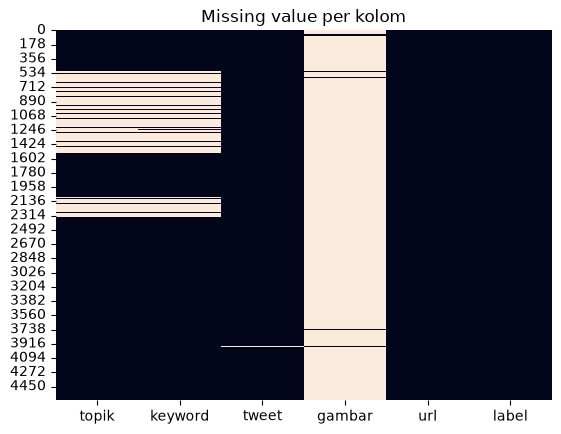

In [9]:
sns.heatmap(df_raw.isnull(), cbar=False)
plt.title('Missing value per kolom')
plt.show()

In [10]:
n_awal = len(data)
mask_kosong = data['teks'].isna() | (data['teks'].astype(str).str.strip() == '')
mask_label  = ~data['label'].isin(['hoax', 'valid', 'tidak_jelas'])
print('Tweet kosong       :', mask_kosong.sum())
print('Label kosong/aneh  :', mask_label.sum())

data = data[~mask_kosong & ~mask_label].reset_index(drop=True)
print(f'Baris: {n_awal} -> {len(data)}')

Tweet kosong       : 18
Label kosong/aneh  : 0
Baris: 4617 -> 4599


Terdapat 18 tweet kosong (0,39% dari data) dan tidak ada label kosong. Tweet kosong tidak dapat diklasifikasikan karena tidak memiliki teks sama sekali, sehingga dilakukan *listwise deletion* (baris dihapus). Setelah langkah ini tersisa 4.599 baris, dan label hanya terdiri dari tiga kategori: `hoax`, `valid`, `tidak_jelas`.

## Duplicate Data Checking

Banyak tweet yang merupakan retweet, quote, atau pesan berantai yang di-copy-paste dengan teks sama atau hampir sama. Jika tidak dihapus **sebelum split**, teks yang sama bisa masuk ke data latih dan data uji sekaligus sehingga skor menjadi palsu. Langkahnya:
1. Normalisasi ringan: lowercase, hapus URL, mention, awalan `RT`, tanda baca, dan rapikan spasi.
2. Hapus duplikat berdasarkan teks hasil normalisasi.
3. Grup teks yang sama tetapi labelnya berbeda dibuang seluruhnya karena labelnya ambigu.

In [11]:
def normalisasi_ringan(t):
    t = t.lower()
    t = re.sub(r'https?://\S+|www\.\S+|pic\.twitter\.com/\S+', ' ', t)
    t = re.sub(r'@\w+', ' ', t)
    t = re.sub(r'^rt\s+', ' ', t)
    t = re.sub(r'[^a-z0-9\s]', ' ', t)
    return re.sub(r'\s+', ' ', t).strip()

data['teks_norm'] = data['teks'].map(normalisasi_ringan)

# tweet yang isinya hanya URL/mention menjadi kosong setelah normalisasi -> dibuang
kosong_norm = data['teks_norm'] == ''
print('Tweet kosong setelah normalisasi (isinya hanya URL/mention):', kosong_norm.sum())
data = data[~kosong_norm].reset_index(drop=True)

dup_persis = data['teks'].duplicated().sum()
dup_norm   = data['teks_norm'].duplicated().sum()
konflik    = data.groupby('teks_norm')['label'].transform('nunique') > 1

print('Duplikat teks persis               :', dup_persis)
print('Duplikat setelah normalisasi ringan:', dup_norm)
print('Baris dalam grup label konflik     :', konflik.sum(),
      f"({data.loc[konflik, 'teks_norm'].nunique()} grup)")

Tweet kosong setelah normalisasi (isinya hanya URL/mention): 4
Duplikat teks persis               : 59
Duplikat setelah normalisasi ringan: 150
Baris dalam grup label konflik     : 35 (13 grup)


In [12]:
# contoh grup duplikat dengan label berbeda
data[konflik].sort_values('teks_norm')[['teks', 'label']].head(8)

,teks,label
778,Banyak yang beranggapan khususnya para wanita bahwa terlalu banyak makan timun bisa menyebabkan vagina 'becek' karen...,tidak_jelas
3170,Banyak yang beranggapan khususnya para wanita bahwa terlalu banyak makan timun bisa menyebabkan vagina 'becek' karen...,valid
1482,Benarkah Minum Kopi Cegah Kejang-kejang pada Balita? | \n@detikcom,tidak_jelas
1484,Benarkah Minum Kopi Cegah Kejang-kejang pada Balita? http://goo.gl/fb/c8JAX,hoax
1742,Benarkah Sup Sirip Ikan Hiu Bermanfaat Bagi Tubuh? http://gaptekupdate.com/2017/01/benarkah-sup-sirip-ikan-hiu-berma...,hoax
1748,Benarkah Sup Sirip Ikan Hiu Bermanfaat bagi Tubuh? http://pekanbaru.tribunnews.com/2017/01/26/benarkah-sup-sirip-ika...,tidak_jelas
1941,Benarkah Sup Sirip Ikan Hiu Bermanfaat Bagi Tubuh? http://gaptekupdate.com/2017/01/benarkah-sup-sirip-ikan-hiu-berma...,hoax
1942,Benarkah Sup Sirip Ikan Hiu Bermanfaat Bagi Tubuh? - http://darwinchai.com/traveling/benarkah-sup-sirip-ikan-hiu-ber...,hoax


In [13]:
n_sebelum = len(data)
data = data[~konflik].drop_duplicates('teks_norm').reset_index(drop=True)
print(f'Baris: {n_sebelum} -> {len(data)}')

Baris: 4595 -> 4432


Ditemukan 4 tweet yang isinya hanya URL/mention, 59 duplikat teks persis, dan **150 duplikat setelah normalisasi ringan**. Normalisasi menangkap lebih banyak duplikat karena tweet yang sama sering hanya berbeda di URL pendek atau mention (contoh: *"Benarkah Sup Sirip Ikan Hiu Bermanfaat Bagi Tubuh?"* muncul berkali-kali dari akun berbeda).

Ada 13 grup (35 baris) yang teksnya identik tetapi labelnya berbeda, misalnya tweet yang sama diberi label `hoax` di satu baris dan `tidak_jelas` di baris lain. Grup seperti ini dibuang seluruhnya karena labelnya tidak konsisten. Total data turun dari 4.595 menjadi **4.432 baris**. Tanpa langkah ini, tweet yang sama bisa masuk ke data latih dan data uji sekaligus sehingga skor model menjadi lebih tinggi dari kemampuan sebenarnya.

## Distribusi Label

,jumlah,persen
label,,
hoax,2905,65.55
tidak_jelas,828,18.68
valid,699,15.77


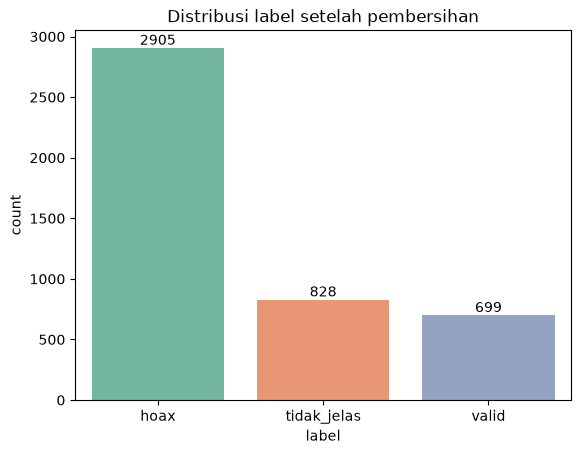

In [14]:
dist = pd.DataFrame({'jumlah': data['label'].value_counts(),
                     'persen': (data['label'].value_counts(normalize=True) * 100).round(2)})
display(dist)

ax = sns.countplot(x='label', data=data, order=dist.index, palette='Set2')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom')
plt.title('Distribusi label setelah pembersihan')
plt.show()

Setelah pembersihan, distribusi label adalah **hoax 2.905 (65,55%)**, **tidak_jelas 828 (18,68%)**, dan **valid 699 (15,77%)**. Kelas tidak seimbang: jumlah `hoax` sekitar 4 kali `valid`. Akibatnya, model yang selalu menebak `hoax` sudah mendapat akurasi 65,5%, sehingga evaluasi harus memakai **F1 makro** dan performa per kelas. Ketidakseimbangan ini ditangani dengan `class_weight='balanced'` pada tahap modeling.

## Exploratory Data Analysis

### Derau (noise) dalam tweet

In [15]:
pola_derau = {
    'URL'                 : r'https?://\S+|www\.\S+',
    'Mention (@user)'     : r'@\w+',
    'Hashtag (#)'         : r'#\w+',
    'Angka'               : r'\d+',
    'Baris baru (\\n)'    : r'\n',
    'Tanda baca berulang' : r'[!?.]{2,}',
    'Huruf berulang (3x+)': r'([A-Za-z])\1{2,}',
    'Awalan RT'           : r'^RT\b',
    'HTML entity (&amp;)' : r'&\w+;',
}
inventaris = {k: data['teks'].str.contains(p, regex=True).sum() for k, p in pola_derau.items()}
inventaris['Karakter emoji'] = data['teks'].map(lambda s: emoji.emoji_count(s) > 0).sum()
inventaris['Nama emoji berbentuk teks'] = data['teks'].str.contains(
    r'face with|smiling face|crying face|folded hands|thumbs up|laughing', case=False, regex=True).sum()

derau = pd.DataFrame({'jumlah_tweet': inventaris})
derau['persen'] = (derau['jumlah_tweet'] / len(data) * 100).round(2)
derau.sort_values('jumlah_tweet', ascending=False)

,jumlah_tweet,persen
Angka,2205,49.75
URL,1432,32.31
Baris baru (\n),1063,23.98
Tanda baca berulang,867,19.56
Hashtag (#),752,16.97
Mention (@user),385,8.69
Huruf berulang (3x+),118,2.66
Nama emoji berbentuk teks,113,2.55
Karakter emoji,29,0.65
Awalan RT,14,0.32


In [16]:
# contoh emoji yang sudah berubah menjadi teks Inggris dan menempel pada kata
data[data['teks'].str.contains('Face with|face with', regex=True)]['teks'].head(3).tolist()

['Patut la dah start batuk batuk, tadi petang bedal rambutan satu tupperwareFace with tears of joy',
 'makan rambutan banyak. batuk tak berhentiFace with cold sweat',
 'ko aku jual Peach Gum Desserts. Di dalamnya ada Peach Gum, Biji Teratai, Jujube, Gojiberry, Snow Fungus, Wintermelon & longan kering. Kuahnya pakai gula batu, jadi lebih sehat. Dessert ini kandungan kolagennya tinggi bgt loh ko Smiling face with smiling eyes segar & sehat bgt! Banyak bgt yg repeat orderFace with tears of joyFace savouring food']

Derau yang paling banyak adalah **angka (49,8% tweet)**, **URL (32,3%)**, baris baru (24,0%), tanda baca berulang seperti `!!!` atau `???` (19,6%), dan hashtag (17,0%). Temuan khusus pada dataset ini: emoji tidak hanya muncul sebagai karakter (0,65%), tetapi lebih sering sudah berubah menjadi **nama emoji dalam bahasa Inggris yang menempel pada kata** (2,55%), contohnya `tupperwareFace with tears of joy`. Pola ini harus dipisahkan dulu sebelum dipetakan dengan kamus emoji, kalau tidak akan menjadi token aneh seperti `tupperwareface`.

### Panjang tweet per label

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
hoax,2905.0,18.9,10.5,2.0,11.0,16.0,23.0,123.0
tidak_jelas,828.0,18.9,10.8,1.0,10.0,16.0,24.0,58.0
valid,699.0,21.1,10.7,5.0,12.0,18.0,30.0,49.0


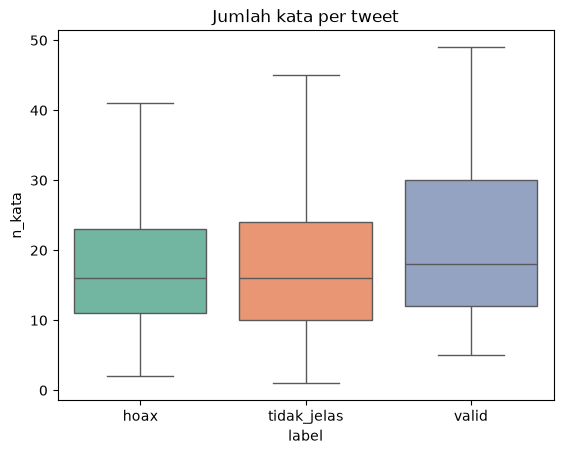

In [17]:
data['n_kata'] = data['teks'].str.split().str.len()
display(data.groupby('label')['n_kata'].describe().round(1))

sns.boxplot(x='label', y='n_kata', data=data, palette='Set2', showfliers=False)
plt.title('Jumlah kata per tweet')
plt.show()

Tweet berlabel `valid` sedikit lebih panjang (rata-rata 21,1 kata, median 18) dibandingkan `hoax` dan `tidak_jelas` (rata-rata 18,9 kata, median 16). Tweet valid cenderung berupa penjelasan atau klarifikasi yang lebih panjang. Namun distribusi ketiga kelas sangat tumpang tindih, sehingga panjang tweet saja tidak cukup untuk membedakan kelas.

### Mengapa `keyword` dan `topik` tidak boleh dipakai sebagai fitur

In [18]:
eda = df_raw.copy()
eda['label'] = eda['label'].astype(str).str.strip().replace({'?': 'tidak_jelas'})
eda['keyword_norm'] = eda['keyword'].fillna('').str.lower().str.strip()

kemurnian = eda.groupby('keyword_norm')['label'].agg(lambda s: s.value_counts(normalize=True).iloc[0])
print('Jumlah keyword unik                   :', len(kemurnian))
print('Keyword dengan 1 label saja (100% murni):', (kemurnian == 1).sum(),
      f'({(kemurnian == 1).mean() * 100:.1f}%)')

# contoh keyword yang langsung mengarah ke satu label
eda[eda['keyword_norm'].str.contains('autis')].groupby(['keyword', 'label']).size()

Jumlah keyword unik                   : 691
Keyword dengan 1 label saja (100% murni): 274 (39.7%)


keyword                      label      
Vaksin penyebab autis        hoax           6
                             tidak_jelas    1
vaksin MMR sebabkan autisme  hoax           4
                             tidak_jelas    1
                             valid          2
dtype: int64

In [19]:
# Bukti kebocoran: model yang HANYA melihat keyword (tanpa isi tweet)
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier

cv_bocor = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
skor_keyword = cross_val_score(
    Pipeline([('tfidf', TfidfVectorizer()), ('model', LogisticRegression(max_iter=2000, class_weight='balanced'))]),
    eda['keyword_norm'], eda['label'], cv=cv_bocor, scoring='f1_macro')
skor_dummy = cross_val_score(DummyClassifier(strategy='most_frequent'), eda['keyword_norm'], eda['label'],
                             cv=cv_bocor, scoring='f1_macro')
print(f'F1 makro model keyword saja : {skor_keyword.mean():.3f}')
print(f'F1 makro kelas mayoritas    : {skor_dummy.mean():.3f}')

F1 makro model keyword saja : 0.466
F1 makro kelas mayoritas    : 0.265


Sebanyak **274 dari 691 keyword (39,7%) hanya berisi satu label**. Contohnya, hampir semua tweet dengan keyword *"Vaksin penyebab autis"* berlabel `hoax`. Model yang **hanya melihat keyword tanpa membaca isi tweet** sudah mencapai F1 makro **0,466**, jauh di atas baseline kelas mayoritas (0,265) dan tidak jauh dari model berbasis isi tweet. Ini membuktikan `keyword` membocorkan label: jika dipakai sebagai fitur, model akan menghafal kata kunci pencarian, bukan belajar ciri tweet hoaks, dan akan gagal pada tweet baru yang tidak dicari dengan kata kunci yang sama. Karena itu `keyword`, `topik`, `gambar`, dan `url` **tidak dipakai sebagai fitur**.

In [20]:
# Kata 'hoax/hoaks' di dalam tweet ternyata tidak otomatis berarti label hoax
ada_kata_hoax = data['teks'].str.contains(r'\bhoa[xk]s?\b', case=False, regex=True)
print('Tweet yang memuat kata hoax/hoaks:', ada_kata_hoax.sum())
data[ada_kata_hoax]['label'].value_counts()

Tweet yang memuat kata hoax/hoaks: 153


label
valid          72
hoax           57
tidak_jelas    24
Name: count, dtype: int64

Dari 153 tweet yang memuat kata *hoax/hoaks*, justru **72 tweet (47%) berlabel `valid`** dan hanya 57 berlabel `hoax`. Tweet yang menyebut "hoax" umumnya adalah klarifikasi atau bantahan ("informasi itu hoax"), sehingga isinya benar. Ini menunjukkan model tidak bisa sekadar mencari kata "hoax"; konteks kalimat lebih penting.

## Pembersihan Teks (Text Cleaning)

Aturan pembersihan yang dipakai (dicatat untuk laporan):

| No | Aturan | Alasan |
|----|--------|--------|
| 1 | `html.unescape` (`&amp;` → `&`) | Merapikan entitas HTML |
| 2 | Pisahkan huruf kecil yang langsung diikuti huruf kapital (`tupperwareFace` → `tupperware Face`, `#FatwaHaramPilihPSI` → `Fatwa Haram Pilih PSI`) | Emoji teks dan hashtag CamelCase sering menempel pada kata |
| 2b | Emoji (karakter maupun nama emoji berbentuk teks) → token Indonesia, misal `emoji_tertawa` | Emosi/ekspresi bisa jadi petunjuk gaya tulisan |
| 3 | Hapus URL, `pic.twitter.com`, mention `@user`, awalan `RT` | Tidak membawa makna isi |
| 4 | Hashtag: tanda `#` dibuang, katanya **dipertahankan** | Kata dalam hashtag sering bermakna (`#hoax`, `#vaksin`) |
| 5 | Lowercase, hapus angka dan karakter non-huruf | Menyeragamkan token |
| 6 | Huruf berulang 3x atau lebih dipendekkan (`yaaa` → `ya`) | Menyatukan variasi penulisan |
| 7 | Normalisasi kata gaul dengan kamus kecil (`yg` → `yang`, `gak` → `tidak`) | Menyatukan variasi kata informal |
| 8 | Penanganan negasi: `tidak benar` → `tidak_benar` | Makna "tidak benar" berbeda dengan "benar" |
| 9 | Stopword removal dan stemming Sastrawi | **Opsional**, hanya dipakai jika lolos uji ablasi |

### Kamus kecil: nama emoji dan kata gaul

Kamus kata gaul disusun dari token pendek yang paling sering muncul di dataset ini, bukan dari daftar umum.

In [21]:
KAMUS_EMOJI = {
    'face with tears of joy': 'emoji_tertawa', 'rolling on the floor laughing': 'emoji_tertawa',
    'grinning face with smiling eyes': 'emoji_senyum', 'smiling face with smiling eyes': 'emoji_senyum',
    'slightly smiling face': 'emoji_senyum', 'grinning face': 'emoji_senyum', 'smiling face': 'emoji_senyum',
    'loudly crying face': 'emoji_menangis', 'crying face': 'emoji_menangis', 'smiling face with tear': 'emoji_menangis',
    'pensive face': 'emoji_sedih', 'weary face': 'emoji_sedih', 'broken heart': 'emoji_sedih',
    'relieved face': 'emoji_lega', 'folded hands': 'emoji_berdoa', 'pleading face': 'emoji_memohon',
    'thumbs up': 'emoji_jempol', 'red heart': 'emoji_cinta',
    'thinking face': 'emoji_berpikir', 'face with monocle': 'emoji_berpikir', 'face with raised eyebrow': 'emoji_berpikir',
    'face screaming in fear': 'emoji_takut', 'astonished face': 'emoji_kaget', 'face with hand over mouth': 'emoji_kaget',
    'exploding head': 'emoji_kaget', 'upside-down face': 'emoji_sindir', 'winking face': 'emoji_kedip',
    'winking face with tongue': 'emoji_kedip', 'see-no-evil monkey': 'emoji_malu',
    'double exclamation mark': 'emoji_seru', 'cross mark': 'emoji_salah', 'check mark': 'emoji_benar',
    'face with cold sweat': 'emoji_cemas', 'face savouring food': 'emoji_lezat', 'face savoring food': 'emoji_lezat',
    'drooling face': 'emoji_lezat', 'expressionless face': 'emoji_datar', 'confused face': 'emoji_bingung',
    'persevering face': 'emoji_sedih', 'tired face': 'emoji_sedih', 'frowning face': 'emoji_sedih',
    'face with rolling eyes': 'emoji_sindir', 'smirking face': 'emoji_sindir', 'grimacing face': 'emoji_canggung',
    'flushed face': 'emoji_kaget', 'face with open mouth': 'emoji_kaget', 'face with medical mask': 'emoji_masker',
    'squinting face with tongue': 'emoji_kedip', 'smiling face with halo': 'emoji_senyum',
    'smiling face with sunglasses': 'emoji_senyum', 'kissing face with closed eyes': 'emoji_cinta',
    'two hearts': 'emoji_cinta', 'sparkling heart': 'emoji_cinta', 'revolving hearts': 'emoji_cinta',
    'clapping hands': 'emoji_tepuk_tangan', 'raised fist': 'emoji_semangat', 'ok hand': 'emoji_jempol',
    'victory hand': 'emoji_jempol', 'waving hand': 'emoji_sapa',
}
# urutkan dari nama terpanjang agar 'smiling face with smiling eyes' tidak terpotong jadi 'smiling face'
POLA_NAMA_EMOJI = re.compile('|'.join(re.escape(k) for k in sorted(KAMUS_EMOJI, key=len, reverse=True)), re.I)

KAMUS_GAUL = {
    'yg': 'yang', 'ga': 'tidak', 'gak': 'tidak', 'gk': 'tidak', 'g': 'tidak', 'nggak': 'tidak', 'ngga': 'tidak',
    'enggak': 'tidak', 'engga': 'tidak', 'tdk': 'tidak', 'tak': 'tidak', 'kalo': 'kalau', 'klo': 'kalau',
    'aja': 'saja', 'udah': 'sudah', 'udh': 'sudah', 'sdh': 'sudah', 'dah': 'sudah', 'utk': 'untuk',
    'krn': 'karena', 'krna': 'karena', 'dgn': 'dengan', 'dg': 'dengan', 'jd': 'jadi', 'tp': 'tapi',
    'jg': 'juga', 'pake': 'pakai', 'tau': 'tahu', 'bs': 'bisa', 'org': 'orang', 'dlm': 'dalam',
    'dpt': 'dapat', 'jgn': 'jangan', 'hrs': 'harus', 'lg': 'lagi', 'bgt': 'banget', 'tsb': 'tersebut',
    'gw': 'saya', 'gue': 'saya', 'gua': 'saya', 'sy': 'saya', 'aku': 'saya', 'trus': 'terus',
    'gitu': 'begitu', 'gini': 'begini', 'ni': 'ini', 'tu': 'itu', 'emg': 'memang', 'blm': 'belum',
    'sm': 'sama', 'kyk': 'seperti', 'kayak': 'seperti', 'gmn': 'bagaimana', 'knp': 'kenapa',
    'ortu': 'orang tua', 'bener': 'benar', 'bnr': 'benar', 'skrg': 'sekarang', 'sbg': 'sebagai',
    'spt': 'seperti', 'sblm': 'sebelum', 'stlh': 'setelah', 'bbrp': 'beberapa', 'dll': 'dan lain lain',
    'yaa': 'ya', 'iya': 'ya', 'cuma': 'hanya', 'biar': 'agar', 'td': 'tadi', 'loh': 'lho', 'nih': 'ini',
}
NEGASI = {'tidak', 'bukan', 'belum', 'jangan', 'tanpa'}
print(len(KAMUS_EMOJI), 'entri emoji |', len(KAMUS_GAUL), 'entri kata gaul')

59 entri emoji | 71 entri kata gaul


In [23]:
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

_stemmer = StemmerFactory().create_stemmer()
_cache_stem = {}
def stem_kata(w):
    if w not in _cache_stem:
        _cache_stem[w] = _stemmer.stem(w)
    return _cache_stem[w]

# kata negasi dikeluarkan dari daftar stopword supaya maknanya tidak hilang
STOPWORDS = set(StopWordRemoverFactory().get_stop_words()) - NEGASI


def ganti_emoji(t):
    t = POLA_NAMA_EMOJI.sub(lambda m: ' ' + KAMUS_EMOJI[m.group(0).lower()] + ' ', t)
    return emoji.replace_emoji(
        t, replace=lambda ch, d: ' ' + KAMUS_EMOJI.get(d['en'].strip(':').replace('_', ' ').lower(), '') + ' ')


def bersihkan_teks(t, gaul=True, negasi=True, stopword=False, stem=False):
    t = html.unescape(t)
    t = re.sub(r'([a-z])([A-Z])', r'\1 \2', t)   # pisahkan kata yang menempel: 'tupperwareFace' -> 'tupperware Face'
    t = ganti_emoji(t)
    t = re.sub(r'https?://\S+|www\.\S+|pic\.twitter\.com/\S+', ' ', t)
    t = re.sub(r'@\w+', ' ', t)
    t = re.sub(r'^\s*RT\b', ' ', t, flags=re.I)
    t = t.replace('#', ' ')
    t = t.lower()
    t = re.sub(r'\d+', ' ', t)
    t = re.sub(r'[^a-z_\s]', ' ', t)
    t = re.sub(r'([a-z])\1{2,}', r'\1', t)
    tokens = t.split()

    if gaul:
        tokens = [x for w in tokens for x in KAMUS_GAUL.get(w, w).split()]
    if stem:
        tokens = [w if '_' in w else stem_kata(w) for w in tokens]
    if negasi:
        hasil, i = [], 0
        while i < len(tokens):
            if tokens[i] in NEGASI and i + 1 < len(tokens):
                hasil.append(tokens[i] + '_' + tokens[i + 1]); i += 2
            else:
                hasil.append(tokens[i]); i += 1
        tokens = hasil
    if stopword:
        tokens = [w for w in tokens if w not in STOPWORDS]
    return ' '.join(tokens)


contoh = data['teks'].iloc[[0, 5]].tolist() + [
    'Buat para ortu yg sdh mantu: "Vaksin Penyebab Autis" itu tdk benar!!! http://fb.me/xyz @user #hoax',
    'makan rambutan banyak. batuk tak berhentiFace with cold sweat yaaa']
for c in contoh:
    print('ASLI  :', c)
    print('BERSIH:', bersihkan_teks(c))
    print()

ASLI  : Mahasiswa ITS buat pembangkit listrik dari kolam air garam. Gimana sob? Satu lagi penemuan sumber energi alternatif. http://ow.ly/i/2X2RP
BERSIH: mahasiswa its buat pembangkit listrik dari kolam air garam gimana sob satu lagi penemuan sumber energi alternatif

ASLI  : Inovasi ini berupa pemanfaatan air garam sebagai sumber energi listrik alternatif untuk kemandirian energi berbasis potensi lokal Madura.
BERSIH: inovasi ini berupa pemanfaatan air garam sebagai sumber energi listrik alternatif untuk kemandirian energi berbasis potensi lokal madura

ASLI  : Buat para ortu yg sdh mantu: "Vaksin Penyebab Autis" itu tdk benar!!! http://fb.me/xyz @user #hoax
BERSIH: buat para orang tua yang sudah mantu vaksin penyebab autis itu tidak_benar hoax

ASLI  : makan rambutan banyak. batuk tak berhentiFace with cold sweat yaaa
BERSIH: makan rambutan banyak batuk tidak_berhenti emoji_cemas ya



## Split Data (Stratified, seed tetap)

Split dilakukan **setelah deduplikasi**, dengan perbandingan 80:20, *stratified* berdasarkan label, dan `random_state=42`. Indeks train/test disimpan ke file agar **semua model memakai split yang sama** dan hasilnya dapat direproduksi. Pembersihan teks bersifat per-baris (tidak belajar dari data), sehingga aman dilakukan sebelum maupun sesudah split.

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
data['y'] = le.fit_transform(data['label'])
KELAS = list(le.classes_)
print(dict(zip(KELAS, range(len(KELAS)))))

train_df, test_df = train_test_split(data, test_size=0.2, stratify=data['y'], random_state=SEED)
train_df.index.to_series().to_csv('train_idx.csv', index=False)
test_df.index.to_series().to_csv('test_idx.csv', index=False)

pd.DataFrame({'train': train_df['label'].value_counts(), 'test': test_df['label'].value_counts()})

{'hoax': 0, 'tidak_jelas': 1, 'valid': 2}


,train,test
label,,
hoax,2324,581
tidak_jelas,662,166
valid,559,140


### Uji ablasi pembersihan teks

Stemming dan stopword removal **tidak langsung dipakai**. Setiap varian pembersihan diuji dengan model yang sama (TF-IDF + Logistic Regression) memakai 5-fold CV di data latih. Varian dengan F1 makro terbaik yang dipakai untuk tahap modeling.

In [25]:
varian = {
    'A. dasar (tanpa kamus gaul & negasi)': dict(gaul=False, negasi=False),
    'B. + kamus gaul'                      : dict(gaul=True,  negasi=False),
    'C. + kamus gaul + negasi'             : dict(gaul=True,  negasi=True),
    'D. C + stopword removal'              : dict(gaul=True,  negasi=True, stopword=True),
    'E. C + stemming Sastrawi'             : dict(gaul=True,  negasi=True, stem=True),
    'F. C + stopword + stemming'           : dict(gaul=True,  negasi=True, stopword=True, stem=True),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
pipe_ablasi = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=3000, class_weight='balanced'))])

hasil_ablasi = []
for nama, opsi in varian.items():
    X_var = train_df['teks'].map(lambda t: bersihkan_teks(t, **opsi))
    s = cross_val_score(pipe_ablasi, X_var, train_df['y'], cv=cv, scoring='f1_macro')
    hasil_ablasi.append({'varian': nama, 'f1_macro': s.mean(), 'std': s.std()})
hasil_ablasi = pd.DataFrame(hasil_ablasi).round(4)
hasil_ablasi

,varian,f1_macro,std
0,A. dasar (tanpa kamus gaul & negasi),0.5432,0.0107
1,B. + kamus gaul,0.5301,0.0178
2,C. + kamus gaul + negasi,0.5237,0.0164
3,D. C + stopword removal,0.5176,0.0117
4,E. C + stemming Sastrawi,0.5279,0.0206
5,F. C + stopword + stemming,0.5278,0.0207


Hasil uji ablasi (TF-IDF + Logistic Regression, 5-fold CV di data latih):

- Varian **A (pembersihan dasar)** memberi F1 makro tertinggi, **0,5432**.
- Menambahkan kamus kata gaul (B, 0,5301) dan penanganan negasi (C, 0,5237) **tidak menaikkan skor**. Penjelasan yang paling mungkin: TF-IDF memakai bigram, sehingga frasa seperti "tidak benar" sudah tertangkap sebagai satu fitur tanpa perlu digabung. Selain itu, sebagian varian penulisan ternyata informatif, misalnya `tak` banyak muncul di tweet klarifikasi dan tweet berbahasa Melayu, sehingga menyamakannya dengan `tidak` justru menghilangkan informasi.
- **Stopword removal paling merugikan** (D, 0,5176), karena kata seperti "apa" dan "benarkah" adalah petunjuk penting untuk kelas `tidak_jelas`.
- **Stemming Sastrawi tidak membantu** (E, 0,5279; F, 0,5278).

Semua selisih berada di kisaran 1–2 standar deviasi, jadi perbedaannya kecil. Berdasarkan hasil ini, pipeline modeling memakai **varian A**: URL, mention, angka, emoji, dan hashtag tetap dibersihkan, tetapi tanpa normalisasi kata gaul, negasi, stopword removal, maupun stemming. Kamus kata gaul dan negasi tetap didokumentasikan dan dapat diuji ulang pada model berbasis embedding.

In [26]:
OPSI_TERPILIH = varian[hasil_ablasi.sort_values('f1_macro', ascending=False).iloc[0]['varian']]
print('Opsi pembersihan yang dipakai:', OPSI_TERPILIH)

train_df['teks_bersih'] = train_df['teks'].map(lambda t: bersihkan_teks(t, **OPSI_TERPILIH))
test_df['teks_bersih']  = test_df['teks'].map(lambda t: bersihkan_teks(t, **OPSI_TERPILIH))
X_train, y_train = train_df['teks_bersih'], train_df['y'].values
X_test,  y_test  = test_df['teks_bersih'],  test_df['y'].values
print('Teks kosong setelah dibersihkan -> train:', (X_train == '').sum(), '| test:', (X_test == '').sum())

Opsi pembersihan yang dipakai: {'gaul': False, 'negasi': False}
Teks kosong setelah dibersihkan -> train: 1 | test: 0


### Kata yang paling sering muncul per label

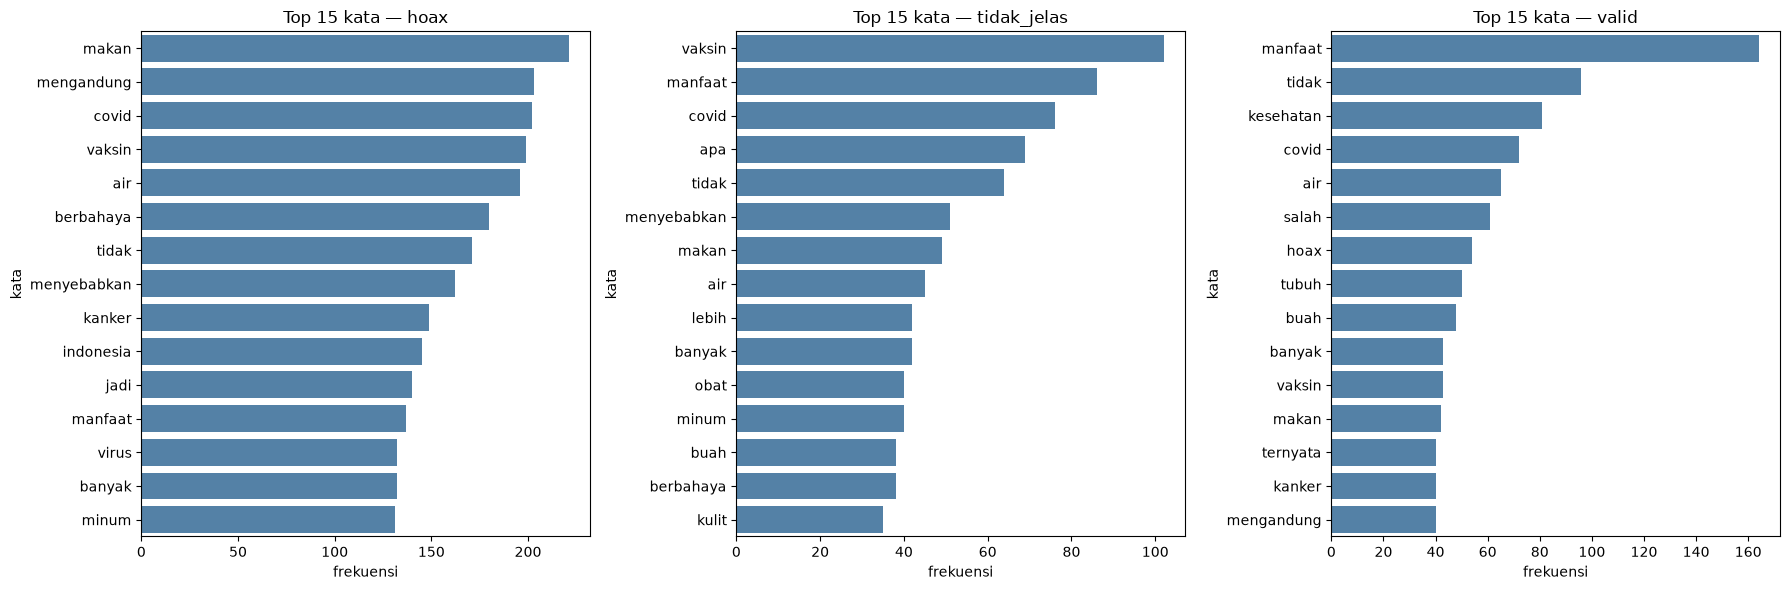

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, kelas in zip(axes, KELAS):
    teks_kelas = train_df.loc[train_df['label'] == kelas, 'teks_bersih']
    hitung = collections.Counter(w for t in teks_kelas for w in t.split() if w not in STOPWORDS and len(w) > 2)
    top = pd.DataFrame(hitung.most_common(15), columns=['kata', 'frekuensi'])
    sns.barplot(x='frekuensi', y='kata', data=top, ax=ax, color='steelblue')
    ax.set_title(f'Top 15 kata — {kelas}')
plt.tight_layout()
plt.show()

Kata yang paling sering muncul sangat mirip di ketiga kelas: `covid`, `vaksin`, `air`, `makan`, dan `manfaat` ada di semua label. Ini wajar karena ketiganya membahas topik kesehatan yang sama. Perbedaan baru terlihat pada kata-kata tertentu: kelas `valid` memuat `salah`, `hoax`, dan `ternyata` (bahasa klarifikasi), kelas `tidak_jelas` banyak memuat `apa` (kalimat tanya), sedangkan kelas `hoax` menempatkan kata klaim seperti `mengandung`, `berbahaya`, dan `menyebabkan` di peringkat atas. Tumpang tindih kosakata inilah yang membuat klasifikasi 3 kelas sulit.

## Feature Engineering: Representasi Teks

Teks harus diubah menjadi angka sebelum masuk ke model. Tiga representasi dibandingkan sesuai rencana kerja:

1. **TF-IDF** (unigram + bigram): memberi bobot tinggi pada kata yang sering muncul di satu tweet tetapi jarang di tweet lain. Ditambah opsi **TF-IDF karakter** (3–5 karakter) yang lebih tahan terhadap salah ketik dan variasi ejaan.
2. **Embedding sederhana — SVD / LSA**: TF-IDF dipadatkan menjadi 200 dimensi dengan *Truncated SVD*, sehingga kata yang sering muncul bersama berada di dimensi yang sama.
3. **FastText**: embedding kata yang dilatih dari data latih (subword 3–6 karakter), lalu vektor tweet = rata-rata vektor katanya. FastText tetap bisa membuat vektor untuk kata yang tidak pernah dilihat, berguna untuk kata gaul dan salah ketik.

Semua transformasi dimasukkan ke dalam `Pipeline`, sehingga TF-IDF, SVD, dan FastText **hanya belajar dari fold latih** di setiap iterasi cross validation (tidak bocor ke fold validasi).

In [29]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import FeatureUnion
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler
from gensim.models import FastText


def hash_tetap(s):
    # hash deterministik agar hasil FastText sama setiap kali dijalankan
    return int(hashlib.md5(str(s).encode()).hexdigest()[:8], 16)


class FastTextVectorizer(BaseEstimator, TransformerMixin):
    """Melatih FastText (gensim) di data latih, lalu tweet = rata-rata vektor kata."""
    def __init__(self, vector_size=100, window=5, min_count=2, epochs=30, seed=SEED):
        self.vector_size = vector_size
        self.window = window
        self.min_count = min_count
        self.epochs = epochs
        self.seed = seed

    def fit(self, X, y=None):
        kalimat = [t.split() for t in X]
        self.model_ = FastText(sentences=kalimat, vector_size=self.vector_size, window=self.window,
                               min_count=self.min_count, epochs=self.epochs, sg=1, min_n=3, max_n=6,
                               seed=self.seed, workers=1, hashfxn=hash_tetap)
        return self

    def transform(self, X):
        out = np.zeros((len(X), self.vector_size), dtype=np.float32)
        for i, t in enumerate(X):
            kata = t.split()
            if kata:
                out[i] = np.mean([self.model_.wv[w] for w in kata], axis=0)
        return out


def tfidf_kata(**kw):
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, **kw)

def tfidf_kata_karakter():
    return FeatureUnion([
        ('kata', tfidf_kata()),
        ('karakter', TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=2,
                                     sublinear_tf=True, max_features=30000))])

# 4. Modeling

Pada tahap modeling dilakukan *Stratified 5-Fold Cross Validation* pada data latih. *Stratified* dipakai agar proporsi `hoax`/`valid`/`tidak_jelas` sama di setiap fold. Dari 5 fold didapat 5 nilai F1 makro, lalu diambil rata-rata dan standar deviasinya. Model yang diuji:

| Kelompok | Model |
|---|---|
| Baseline | Kelas mayoritas (`DummyClassifier`) |
| TF-IDF + linear | Logistic Regression, Linear SVM, Complement Naive Bayes, Passive Aggressive (metode paper rujukan) |
| Embedding sederhana | SVD (LSA) 200 dimensi + Logistic Regression |
| FastText | FastText (gensim) + Logistic Regression |
| Ensemble | Random Forest, XGBoost, LightGBM |

Penanganan ketidakseimbangan kelas: `class_weight='balanced'` untuk model yang mendukung, dan `sample_weight` seimbang untuk XGBoost. Model terbaik ditentukan dari **F1 makro tertinggi**.

## Cross Validation

In [32]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, f1_score, accuracy_score, classification_report, confusion_matrix
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.linear_model import PassiveAggressiveClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier


class BalancedXGBClassifier(XGBClassifier):
    """XGBoost tidak punya class_weight, jadi bobot seimbang dihitung otomatis saat fit."""
    def fit(self, X, y, **kwargs):
        return super().fit(X, y, sample_weight=compute_sample_weight('balanced', y), **kwargs)


models = {
    'Majority (baseline)': Pipeline([('fitur', tfidf_kata()), ('model', DummyClassifier(strategy='most_frequent'))]),
    'TF-IDF + LogReg'    : Pipeline([('fitur', tfidf_kata()), ('model', LogisticRegression(max_iter=3000, class_weight='balanced'))]),
    'TF-IDF + LinearSVC' : Pipeline([('fitur', tfidf_kata()), ('model', LinearSVC(class_weight='balanced'))]),
    'TF-IDF + ComplementNB': Pipeline([('fitur', tfidf_kata()), ('model', ComplementNB())]),
    'TF-IDF + PassiveAggressive (paper)': Pipeline([('fitur', tfidf_kata()),
                            ('model', PassiveAggressiveClassifier(class_weight='balanced', random_state=SEED))]),
    'SVD 200 + LogReg'   : Pipeline([('fitur', tfidf_kata()), ('svd', TruncatedSVD(200, random_state=SEED)),
                            ('scaler', StandardScaler()), ('model', LogisticRegression(max_iter=3000, class_weight='balanced'))]),
    'FastText + LogReg'  : Pipeline([('fitur', FastTextVectorizer()), ('scaler', StandardScaler()),
                            ('model', LogisticRegression(max_iter=3000, class_weight='balanced'))]),
    'TF-IDF + RandomForest': Pipeline([('fitur', tfidf_kata(max_features=10000)),
                            ('model', RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample',
                                                             n_jobs=-1, random_state=SEED))]),
    'TF-IDF + XGBoost'   : Pipeline([('fitur', tfidf_kata(max_features=10000)),
                            ('model', BalancedXGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6,
                                                            subsample=0.8, colsample_bytree=0.5, tree_method='hist',
                                                            n_jobs=-1, random_state=SEED, verbosity=0))]),
    'TF-IDF + LightGBM'  : Pipeline([('fitur', tfidf_kata(max_features=10000)),
                            ('model', LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
                                                     colsample_bytree=0.5, class_weight='balanced',
                                                     random_state=SEED, verbose=-1, n_jobs=-1))]),
}

scoring = {'f1_macro': 'f1_macro', 'accuracy': 'accuracy'}
for i, k in enumerate(KELAS):
    scoring[f'f1_{k}'] = make_scorer(f1_score, labels=[i], average='macro', zero_division=0)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
hasil_cv = []
for nama, pipe in models.items():
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1, error_score='raise')
    baris = {'model': nama,
             'f1_macro': s['test_f1_macro'].mean(), 'std_f1_macro': s['test_f1_macro'].std(),
             'accuracy': s['test_accuracy'].mean()}
    for k in KELAS:
        baris[f'f1_{k}'] = s[f'test_f1_{k}'].mean()
    baris['waktu_fit_detik'] = s['fit_time'].mean()
    hasil_cv.append(baris)
    print(f"{nama:38s} F1 makro = {baris['f1_macro']:.4f} ± {baris['std_f1_macro']:.4f}")

Majority (baseline)                    F1 makro = 0.2640 ± 0.0001
TF-IDF + LogReg                        F1 makro = 0.5432 ± 0.0107
TF-IDF + LinearSVC                     F1 makro = 0.5187 ± 0.0144
TF-IDF + ComplementNB                  F1 makro = 0.4821 ± 0.0127
TF-IDF + PassiveAggressive (paper)     F1 makro = 0.4934 ± 0.0125
SVD 200 + LogReg                       F1 makro = 0.4834 ± 0.0091


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


FastText + LogReg                      F1 makro = 0.4413 ± 0.0127
TF-IDF + RandomForest                  F1 makro = 0.4043 ± 0.0217
TF-IDF + XGBoost                       F1 makro = 0.5117 ± 0.0167
TF-IDF + LightGBM                      F1 makro = 0.4990 ± 0.0149


In [33]:
hasil_cv = pd.DataFrame(hasil_cv).sort_values('f1_macro', ascending=False).reset_index(drop=True)
hasil_cv.round(4)

,model,f1_macro,std_f1_macro,accuracy,f1_hoax,f1_tidak_jelas,f1_valid,waktu_fit_detik
0,TF-IDF + LogReg,0.5432,0.0107,0.6375,0.7591,0.3954,0.4750,0.1440
1,TF-IDF + LinearSVC,0.5187,0.0144,0.6587,0.7884,0.3329,0.4350,0.0713
2,TF-IDF + XGBoost,0.5117,0.0167,0.6260,0.7564,0.3362,0.4426,4.6105
3,TF-IDF + LightGBM,0.4990,0.0149,0.6104,0.7401,0.3226,0.4341,6.7846
4,TF-IDF + PassiveAggressive (paper),0.4934,0.0125,0.6477,0.7842,0.3189,0.3771,0.0630
5,SVD 200 + LogReg,0.4834,0.0091,0.5422,0.6577,0.3692,0.4233,0.3967
6,TF-IDF + ComplementNB,0.4821,0.0127,0.6575,0.7882,0.2683,0.3898,0.0533
7,FastText + LogReg,0.4413,0.0127,0.4889,0.5962,0.3316,0.3960,9.8262
8,TF-IDF + RandomForest,0.4043,0.0217,0.6742,0.8003,0.1174,0.2954,0.7646
9,Majority (baseline),0.2640,0.0001,0.6556,0.7920,0.0000,0.0000,0.0519


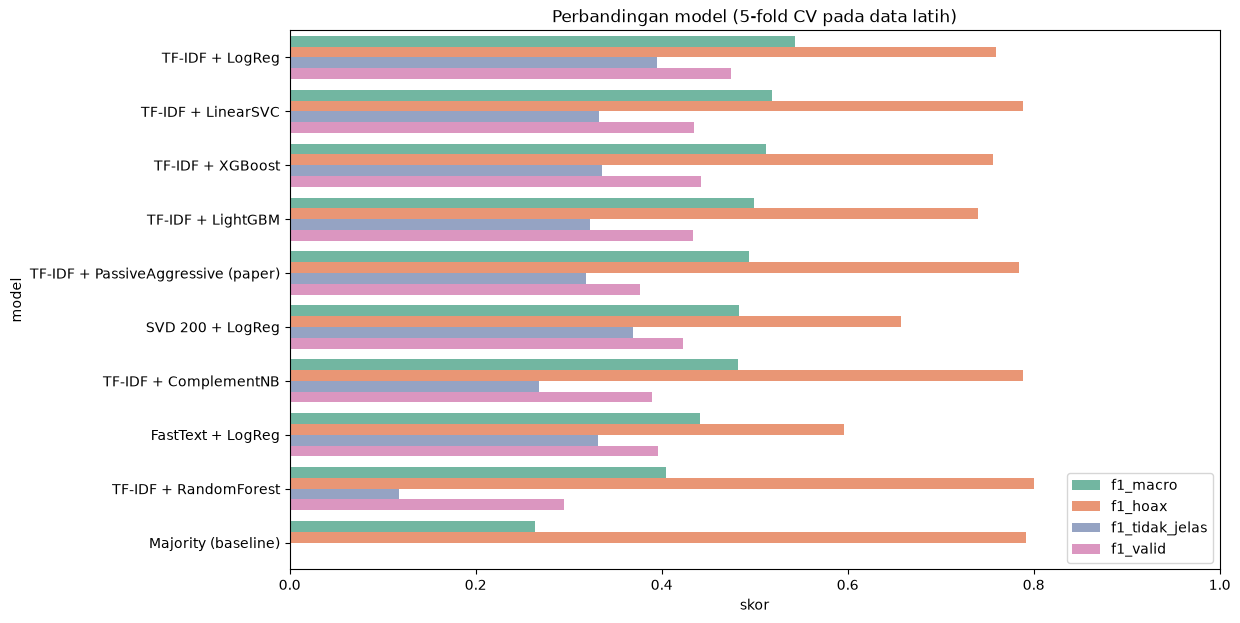

In [34]:
plot_cv = hasil_cv.melt(id_vars='model', value_vars=['f1_macro'] + [f'f1_{k}' for k in KELAS],
                        var_name='metrik', value_name='skor')
plt.figure(figsize=(12, 7))
sns.barplot(y='model', x='skor', hue='metrik', data=plot_cv, palette='Set2')
plt.title('Perbandingan model (5-fold CV pada data latih)')
plt.xlim(0, 1)
plt.legend(loc='lower right')
plt.show()

Hasil 5-fold cross validation di data latih:

1. **TF-IDF + Logistic Regression** adalah model terbaik dengan F1 makro **0,5432 ± 0,0107**, sekaligus memiliki F1 tertinggi untuk kelas kecil (`tidak_jelas` 0,395 dan `valid` 0,475).
2. **TF-IDF + LinearSVC** di posisi kedua (0,5187). Model ensemble **XGBoost (0,5120)** dan **LightGBM (0,4990)** tidak mengungguli model linear; fitur TF-IDF bersifat *sparse* dengan ribuan dimensi, kondisi yang lebih cocok untuk model linear daripada model berbasis pohon.
3. **Passive Aggressive (metode paper rujukan)** mendapat 0,4934. Paper melaporkan akurasi 91,8%, tetapi pada skema 2 kelas tanpa deduplikasi. Pada skema 3 kelas yang sudah dideduplikasi, akurasinya 0,648.
4. **Embedding sederhana (SVD, 0,4834)** dan **FastText (0,4405)** lebih rendah dari TF-IDF. Dengan data latih sekitar 3.500 tweet, embedding yang dilatih dari nol belum cukup kaya.
5. **Random Forest** menjadi contoh nyata mengapa akurasi menyesatkan: akurasinya **paling tinggi (0,674)**, tetapi F1 makronya terendah kedua (0,401) karena hampir tidak pernah menebak `tidak_jelas` dengan benar (F1 0,11).
6. Semua model jauh di atas baseline kelas mayoritas (F1 makro 0,264), yang akurasinya 0,656 tanpa mempelajari apa pun.

Dua model terbaik, **TF-IDF + Logistic Regression** dan **TF-IDF + LinearSVC**, dilanjutkan ke pengujian pada data uji.

## Modeling 2 Best Model

Dua model dengan F1 makro CV tertinggi dilatih ulang di seluruh data latih, lalu diuji **satu kali** pada data uji.

In [35]:
def evaluasi(nama, y_true, y_pred):
    baris = {'Model': nama,
             'F1 makro': f1_score(y_true, y_pred, average='macro'),
             'Akurasi': accuracy_score(y_true, y_pred)}
    for i, k in enumerate(KELAS):
        baris[f'F1 {k}'] = f1_score(y_true, y_pred, labels=[i], average='macro', zero_division=0)
    return pd.DataFrame([baris]).round(4)

top2 = hasil_cv.loc[hasil_cv['model'] != 'Majority (baseline)', 'model'].head(2).tolist()
print('Dua model terbaik:', top2)

hasil_test, pipes_fit = [], {}
for nama in top2:
    p = clone(models[nama]).fit(X_train, y_train)
    pipes_fit[nama] = p
    hasil_test.append(evaluasi(f'{nama}; Before Tuning', y_test, p.predict(X_test)))

baseline_fit = clone(models['Majority (baseline)']).fit(X_train, y_train)
hasil_test.append(evaluasi('Majority (baseline)', y_test, baseline_fit.predict(X_test)))
display(pd.concat(hasil_test, ignore_index=True))

Dua model terbaik: ['TF-IDF + LogReg', 'TF-IDF + LinearSVC']


,Model,F1 makro,Akurasi,F1 hoax,F1 tidak_jelas,F1 valid
0,TF-IDF + LogReg; Before Tuning,0.5175,0.6167,0.7462,0.3402,0.4663
1,TF-IDF + LinearSVC; Before Tuning,0.5308,0.6697,0.7987,0.3299,0.4638
2,Majority (baseline),0.2639,0.6550,0.7916,0.0000,0.0000


Pada data uji (887 tweet), LinearSVC mendapat F1 makro 0,5308 dan Logistic Regression 0,5175. Urutannya berbeda dengan hasil CV, tetapi selisihnya kecil (0,013) dan masih dalam variasi yang wajar untuk data uji berukuran 887 tweet. Pemilihan model untuk tuning tetap berdasarkan **hasil CV** (Logistic Regression), agar data uji tidak ikut dipakai untuk memilih model. Kedua model jauh di atas baseline kelas mayoritas (F1 makro 0,264) meskipun akurasi baseline (0,655) hampir sama dengan model.

### Hyper Parameter Tuning

Setelah memilih model terbaik, langkah berikutnya adalah mencari kombinasi *hyperparameter* yang paling optimal. *Hyperparameter* adalah pengaturan yang tidak dipelajari model dari data dan harus ditentukan sebelum pelatihan, misalnya kekuatan regularisasi `C` atau rentang n-gram TF-IDF.

- **Model:** model terbaik dari cross validation
- **Search Space:** rentang n-gram kata, `min_df`, pemakaian TF-IDF karakter (dipakai/tidak), dan parameter `C`
- **Optimation Criteria:** `F1 makro`
- **Search Method:** `RandomizedSearchCV` (n_iter = 20, 5-fold stratified)

#### Parameter yang di-tuning

| **Parameter** | **Deskripsi** | **Default** |
|---|---|---|
| **fitur__kata__ngram_range** | Panjang n-gram kata pada TF-IDF | (1, 2) |
| **fitur__kata__min_df** | Minimal jumlah dokumen agar kata dipakai | 2 |
| **fitur__karakter** | TF-IDF karakter 3–5 dipakai atau tidak (`'drop'`) | dipakai |
| **model__C** | Kekuatan regularisasi (makin kecil makin kuat) | 1.0 |

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

model_terbaik = top2[0]
estimator_dasar = clone(models[model_terbaik]).named_steps['model']
print('Model yang di-tuning:', model_terbaik, '->', type(estimator_dasar).__name__)

pipe_hyper = Pipeline([('fitur', tfidf_kata_karakter()), ('model', clone(estimator_dasar))])

param_grid = {
    'fitur__kata__ngram_range': [(1, 1), (1, 2), (1, 3)],
    'fitur__kata__min_df'     : [1, 2, 3],
    'fitur__karakter'         : ['drop', TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=2,
                                                         sublinear_tf=True, max_features=30000)],
}
if hasattr(estimator_dasar, 'C'):
    param_grid['model__C'] = [0.05, 0.1, 0.3, 0.5, 1, 2, 3, 5, 10]
elif hasattr(estimator_dasar, 'alpha'):
    param_grid['model__alpha'] = [0.01, 0.05, 0.1, 0.3, 0.5, 1.0]

model_cv = RandomizedSearchCV(pipe_hyper, param_distributions=param_grid, n_iter=20,
                              scoring='f1_macro', cv=cv, random_state=SEED, n_jobs=1)
model_cv.fit(X_train, y_train)

Model yang di-tuning: TF-IDF + LogReg -> LogisticRegression


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=3000))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'fitur__karakter': ['drop', TfidfVectoriz...inear_tf=True)], 'fitur__kata__min_df': [1, 2, ...], 'fitur__kata__ngram_range': [(1, ...), (1, ...), ...], 'model__C': [0.05, 0.1, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and p

In [31]:
print(model_cv.best_params_)
print('F1 makro CV terbaik:', round(model_cv.best_score_, 4))

{'model__C': 2, 'fitur__kata__ngram_range': (1, 3), 'fitur__kata__min_df': 1, 'fitur__karakter': TfidfVectorizer(analyzer='char_wb', max_features=30000, min_df=2,
                ngram_range=(3, 5), sublinear_tf=True)}
F1 makro CV terbaik: 0.5439


In [32]:
pd.DataFrame(model_cv.cv_results_).sort_values(by='rank_test_score')[
    ['params', 'mean_test_score', 'std_test_score', 'rank_test_score']].head(5)

,params,mean_test_score,std_test_score,rank_test_score
17,"{'model__C': 2, 'fitur__kata__ngram_range': (1, 3), 'fitur__kata__min_df': 1, 'fitur__karakter': TfidfVectorizer(ana...",0.543852,0.015477,1
4,"{'model__C': 1, 'fitur__kata__ngram_range': (1, 2), 'fitur__kata__min_df': 1, 'fitur__karakter': TfidfVectorizer(ana...",0.541622,0.012535,2
11,"{'model__C': 0.5, 'fitur__kata__ngram_range': (1, 1), 'fitur__kata__min_df': 1, 'fitur__karakter': TfidfVectorizer(a...",0.541615,0.012660,3
15,"{'model__C': 0.5, 'fitur__kata__ngram_range': (1, 1), 'fitur__kata__min_df': 2, 'fitur__karakter': 'drop'}",0.540477,0.005712,4
0,"{'model__C': 2, 'fitur__kata__ngram_range': (1, 3), 'fitur__kata__min_df': 3, 'fitur__karakter': TfidfVectorizer(ana...",0.538992,0.018458,5


In [33]:
pipe_tuning = model_cv.best_estimator_
y_pred_tuning = pipe_tuning.predict(X_test)

before = evaluasi(f'{model_terbaik}; Before Tuning', y_test, pipes_fit[model_terbaik].predict(X_test))
after  = evaluasi(f'{model_terbaik}; After Tuning',  y_test, y_pred_tuning)
display(pd.concat([before, after], ignore_index=True))

,Model,F1 makro,Akurasi,F1 hoax,F1 tidak_jelas,F1 valid
0,TF-IDF + LogReg; Before Tuning,0.5175,0.6167,0.7462,0.3402,0.4663
1,TF-IDF + LogReg; After Tuning,0.5384,0.6573,0.7852,0.3503,0.4797


Berdasarkan hyperparameter tuning menggunakan random search dengan n_iter = 20, didapatkan parameter terbaik berikut:

| **Parameter** | **Default** | **Best Value** |
|---|---|---|
| **fitur__kata__ngram_range** | (1, 2) | (1, 3) |
| **fitur__kata__min_df** | 2 | 1 |
| **fitur__karakter** | (tidak dipakai di model awal) | TF-IDF karakter 3–5 dipakai |
| **model__C** | 1.0 | 2 |

Pada CV, kenaikan F1 makro sangat kecil (0,5432 → 0,5439). Pada data uji kenaikannya lebih terlihat, **F1 makro 0,5175 → 0,5384** dan akurasi 0,6167 → 0,6573, dengan F1 `valid` naik ke 0,480 dan `tidak_jelas` ke 0,350. **TF-IDF karakter** dipakai di 4 dari 5 kombinasi terbaik, karena fitur karakter lebih tahan terhadap salah ketik dan variasi ejaan. Karena F1 makro CV setelah tuning sedikit lebih tinggi, model **after tuning** dipakai sebagai model final.

In [34]:
# model final dipilih berdasarkan F1 makro CV (bukan berdasarkan data uji), agar data uji tetap jujur
skor_cv_before = hasil_cv.loc[hasil_cv['model'] == model_terbaik, 'f1_macro'].iloc[0]
if model_cv.best_score_ > skor_cv_before:
    pipe_final, nama_final = pipe_tuning, f'{model_terbaik} (after tuning)'
else:
    pipe_final, nama_final = pipes_fit[model_terbaik], f'{model_terbaik} (before tuning)'
y_pred = pipe_final.predict(X_test)
print('Model final:', nama_final)
print(f'F1 makro CV before = {skor_cv_before:.4f} | after = {model_cv.best_score_:.4f}')

Model final: TF-IDF + LogReg (after tuning)
F1 makro CV before = 0.5432 | after = 0.5439


## Confusion Matrix

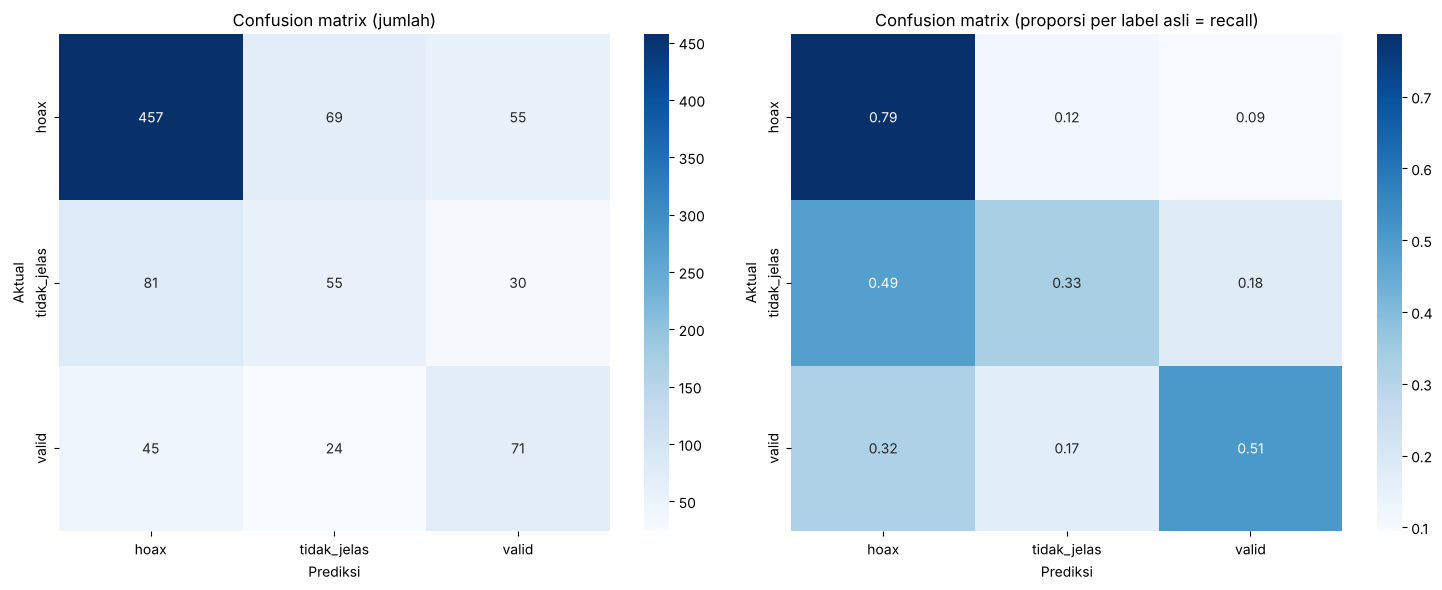

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=KELAS, yticklabels=KELAS, ax=axes[0])
axes[0].set_title('Confusion matrix (jumlah)')
cm_norm = confusion_matrix(y_test, y_pred, normalize='true')
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', xticklabels=KELAS, yticklabels=KELAS, ax=axes[1])
axes[1].set_title('Confusion matrix (proporsi per label asli = recall)')
for ax in axes:
    ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')
plt.tight_layout()
plt.show()

In [36]:
print(classification_report(y_test, y_pred, target_names=KELAS, digits=4))

              precision    recall  f1-score   support

        hoax     0.7839    0.7866    0.7852       581
 tidak_jelas     0.3716    0.3313    0.3503       166
       valid     0.4551    0.5071    0.4797       140

    accuracy                         0.6573       887
   macro avg     0.5369    0.5417    0.5384       887
weighted avg     0.6548    0.6573    0.6556       887



Model final mendapat **F1 makro 0,538** dan akurasi 0,657 pada data uji. Per kelas:

| Kelas | Precision | Recall | F1 | Jumlah data uji |
|---|---|---|---|---|
| hoax | 0,784 | 0,787 | 0,785 | 581 |
| tidak_jelas | 0,372 | 0,331 | 0,350 | 166 |
| valid | 0,455 | 0,507 | 0,480 | 140 |

- **Kelas `hoax` dikenali paling baik**: 457 dari 581 hoaks terdeteksi. Hoaks yang benar-benar lolos sebagai `valid` hanya 55 tweet (9,5%); 69 tweet lainnya masuk `tidak_jelas`, yang dalam praktik masih bisa diteruskan ke pemeriksaan manual.
- **Kelas `tidak_jelas` paling sulit** (F1 0,350). Hampir setengahnya (81 dari 166) diprediksi `hoax`. Isi tweet `tidak_jelas` memang mirip hoaks (klaim kesehatan tanpa kepastian), dan label ini sendiri ambigu.
- **Kelas `valid`** mendapat recall 0,507: sekitar separuh tweet valid dikenali, sisanya tertukar dengan `hoax` (45) dan `tidak_jelas` (24).

Kesalahan terbesar adalah pertukaran antara `hoax` dan `tidak_jelas` di kedua arah (81 + 69 tweet).

### Error Analysis

Melihat contoh tweet yang salah diklasifikasikan untuk memahami pola kesalahan model (pengganti *residual analysis* pada regresi).

In [37]:
df_error = test_df[['teks', 'label']].copy()
df_error['prediksi'] = le.inverse_transform(y_pred)
df_error = df_error[df_error['label'] != df_error['prediksi']]
print('Jumlah salah klasifikasi:', len(df_error), 'dari', len(test_df))
display(df_error.groupby(['label', 'prediksi']).size().rename('jumlah').reset_index()
        .sort_values('jumlah', ascending=False))

Jumlah salah klasifikasi: 304 dari 887


,label,prediksi,jumlah
2,tidak_jelas,hoax,81
0,hoax,tidak_jelas,69
1,hoax,valid,55
4,valid,hoax,45
3,tidak_jelas,valid,30
5,valid,tidak_jelas,24


In [38]:
for (asli, pred), grup in df_error.groupby(['label', 'prediksi']):
    print(f'=== Aktual: {asli}  ->  Prediksi: {pred}')
    for t in grup['teks'].head(3):
        print('  -', t[:200].replace('\n', ' '))
    print()

=== Aktual: hoax  ->  Prediksi: tidak_jelas
  - Selama miras di indonesia halal ga akan deh australia bener" ga mau kesini #baliboycott
  - Apakah Menelan Sperma Aman dan Tidak Menyebabkan Hamil http://sehatobat.com/apakah-menelan-sperma-aman-dan-tidak-menyebabkan-hamil/
  - ALBINO disebabkan oleh makan timun menyebabkan keputihan pada kulit

=== Aktual: hoax  ->  Prediksi: valid
  - 5 Manfaat Saffron untuk Kecantikan, Bisa Usir Jerawat Lho! http://dlvr.it/S4hjQV
  - KHILAFAH MEMULIAKAN AJARAN ISLAM. Oleh: Syah Revolter Beredar berita bahwa Kemenag akan menghapus materi tentang 'perang' dari kurikulum madrasah. Alasannya, agar Islam tidak lagi dijuluki sebagai aga
  - Anies Baswedan dinobatkan menjadi gubernur terbaik dunia?  Ini adalah foto Gubernur Jakarta Anies dan peserta forum walikota dunia #WCSMF lainnya di tahun 2019. Forum itu tidak menganugerahkan gelar "

=== Aktual: tidak_jelas  ->  Prediksi: hoax
  - Eitss, kelebihan konsumsi daging kambing dan sapi akan berefek langsung, 

Dari 887 tweet uji, 304 salah diklasifikasikan. Pola yang terlihat dari contoh di atas:

1. **Hoaks dengan gaya bahasa berita/promosi diprediksi `valid`**, misalnya *"5 Manfaat Saffron untuk Kecantikan, Bisa Usir Jerawat Lho!"*. Tidak ada kata yang menandakan hoaks; benar-tidaknya klaim hanya bisa diketahui dengan pengetahuan di luar teks.
2. **Tweet tanya atau opini masuk `tidak_jelas`** walaupun berlabel `hoax`, contohnya *"Apakah Menelan Sperma Aman dan Tidak Menyebabkan Hamil"*. Model belajar bahwa kalimat tanya cenderung `tidak_jelas`.
3. **Tweet `tidak_jelas` yang berisi klaim kesehatan diprediksi `hoax`**, contohnya klaim efek konsumsi daging kambing. Secara teks sulit dibedakan dari hoaks.
4. **Tweet yang menyebut kata "hoax" cenderung diprediksi `valid`**, walaupun labelnya `tidak_jelas`, contohnya *"Dari pusat bilang kalau info ... harus ada sertifikat vaksin itu hoax. Tapi di tingkat bawah aturan ini masih berlaku"*. Model terlalu bergantung pada kata bantahan.

Kesalahan-kesalahan ini menunjukkan bahwa deteksi hoaks hanya dari teks memiliki batas: model mempelajari **gaya penulisan**, bukan memeriksa **kebenaran fakta**.

## Feature Importance

Untuk model linear, bobot (koefisien) setiap kata per kelas menunjukkan kata yang paling mendorong prediksi ke kelas tersebut.

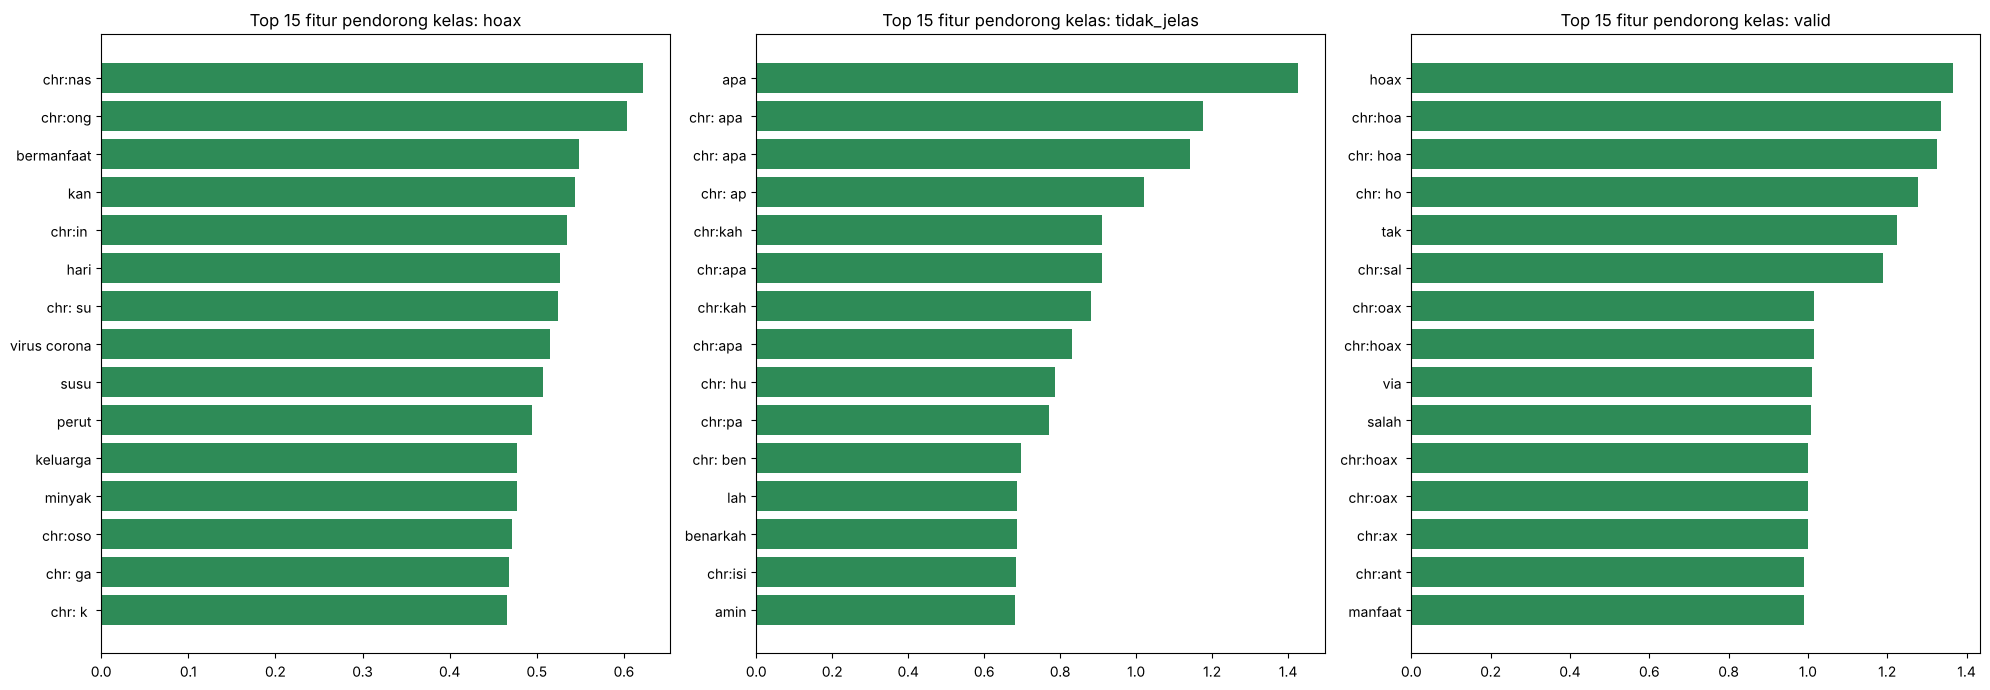

In [39]:
fitur_step = pipe_final.named_steps['fitur']
model_step = pipe_final.named_steps['model']

if hasattr(model_step, 'coef_'):
    nama_fitur = fitur_step.get_feature_names_out()
    fig, axes = plt.subplots(1, 3, figsize=(20, 7))
    for i, (ax, kelas) in enumerate(zip(axes, KELAS)):
        bobot = model_step.coef_[i]
        idx = np.argsort(bobot)[-15:]
        ax.barh([nama_fitur[j].replace('kata__', '').replace('karakter__', 'chr:') for j in idx], bobot[idx],
                color='seagreen')
        ax.set_title(f'Top 15 fitur pendorong kelas: {kelas}')
    plt.tight_layout()
    plt.show()
else:
    print('Model final bukan model linear; gunakan feature_importances_ atau SHAP.')

Dari bobot model Logistic Regression terlihat fitur yang paling mendorong tiap kelas:

1. **`valid`**: kata `hoax`, `salah`, `tak`, dan potongan karakter `hoa`/`oax`. Tweet valid di dataset ini banyak berupa **klarifikasi atau bantahan** ("itu hoax", "informasi salah"), sejalan dengan temuan EDA bahwa 47% tweet yang menyebut "hoax" berlabel valid.
2. **`tidak_jelas`**: kata tanya `apa`, `benarkah`, dan akhiran `-kah`. Tweet yang **bertanya atau meragukan** suatu klaim cenderung dilabeli tidak jelas.
3. **`hoax`**: kata seperti `bermanfaat`, `virus corona`, `susu`, `perut`, `minyak`, dan `keluarga`. Ini mencerminkan klaim kesehatan dan ajakan berbagi ke keluarga yang khas pesan berantai.

Fitur-fitur ini masuk akal dan dapat dijelaskan, tetapi juga menunjukkan model bergantung pada **gaya bahasa** (bantahan, pertanyaan, klaim manfaat), bukan pada isi fakta.

### Limitation

Uji ketahanan: bagaimana performa model jika diuji pada **keyword yang tidak pernah dilihat** saat latihan (`StratifiedGroupKFold`, group = keyword).

In [40]:
from sklearn.model_selection import StratifiedGroupKFold

# keyword HANYA dipakai sebagai pengelompokan fold, bukan fitur; diambil ulang lewat teks tweet asli
peta_keyword = df_raw.dropna(subset=['tweet']).drop_duplicates('tweet').set_index('tweet')['keyword']
grup_keyword = train_df['teks'].map(peta_keyword).fillna('tanpa_keyword').str.lower().str.strip()

skor_grup = cross_val_score(clone(pipe_final), X_train, y_train, groups=grup_keyword,
                            cv=StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED), scoring='f1_macro')
skor_biasa = cross_val_score(clone(pipe_final), X_train, y_train, cv=cv, scoring='f1_macro')
print(f'F1 makro StratifiedKFold biasa        : {skor_biasa.mean():.4f} ± {skor_biasa.std():.4f}')
print(f'F1 makro keyword tak terlihat (group) : {skor_grup.mean():.4f} ± {skor_grup.std():.4f}')

F1 makro StratifiedKFold biasa        : 0.5439 ± 0.0155
F1 makro keyword tak terlihat (group) : 0.4935 ± 0.0195


Model klasifikasi hoaks ini memiliki beberapa keterbatasan yang harus dipahami:

1. **Performa turun pada topik baru.** Jika diuji pada keyword yang tidak pernah dilihat saat latihan, F1 makro turun dari **0,544 menjadi 0,494**. Sebagian kemampuan model berasal dari mengenali topik yang sudah pernah muncul, sehingga untuk isu hoaks yang benar-benar baru performanya lebih rendah.
2. **Model membaca gaya tulisan, bukan memeriksa fakta.** Hoaks yang ditulis dengan gaya berita yang rapi dapat lolos sebagai `valid`.
3. **Kelas `tidak_jelas` masih sulit** (F1 sekitar 0,35), karena labelnya sendiri ambigu.
4. **Cakupan data terbatas**: sekitar 4.400 tweet, didominasi topik kesehatan, dan sebagian tweet berbahasa Melayu. Model belum tentu andal untuk topik lain seperti politik atau bencana.
5. **Model hanya cocok sebagai penyaring awal (triage)**, bukan pengganti tim cek fakta.

# 5. Conclusion
Berdasarkan hasil pemodelan klasifikasi hoaks 3 kelas:

- Dari 10 model yang diuji pada split dan fold yang sama, **TF-IDF (kata 1–3 gram + karakter 3–5 gram) + Logistic Regression** merupakan model terbaik, dengan **F1 makro 0,538**, akurasi 0,657, F1 `hoax` 0,785, F1 `valid` 0,480, dan F1 `tidak_jelas` 0,350 pada data uji.
- Model **jauh lebih baik dari baseline kelas mayoritas** (F1 makro 0,264). Akurasi baseline hampir sama (0,655), sehingga akurasi tidak bisa dipakai untuk menilai model pada data ini.
- Model ensemble (XGBoost, LightGBM, Random Forest), embedding SVD, dan FastText **tidak mengungguli** model linear berbasis TF-IDF. Random Forest bahkan memiliki akurasi tertinggi tetapi F1 makro hampir terendah.
- Dibandingkan paper rujukan yang melaporkan akurasi 91,8% (2 kelas, tanpa deduplikasi), hasil ini lebih rendah tetapi **lebih realistis**, karena memakai 3 kelas, deduplikasi sebelum split, tanpa fitur `keyword` yang bocor, serta dievaluasi dengan F1 makro dan cross validation.
- Uji ablasi menunjukkan **stemming dan stopword removal tidak membantu**; stopword removal justru menurunkan skor karena menghapus kata tanya yang penting untuk kelas `tidak_jelas`.
- Fitur paling berpengaruh: kata **bantahan** (`hoax`, `salah`) untuk kelas `valid`, kata **tanya** (`apa`, `benarkah`) untuk `tidak_jelas`, dan kata **klaim kesehatan/ajakan berbagi** untuk `hoax`.
- Kelas tersulit adalah **`tidak_jelas`**, yang paling sering tertukar dengan `hoax`.

# 6. Recommendation

<b>1. Rekomendasi Berdasarkan Bisnis</b>

- Gunakan model sebagai **penyaring awal**: tweet yang diprediksi `hoax` atau `tidak_jelas` dimasukkan ke antrian tim cek fakta. Dengan aturan ini, **90,5% hoaks** di data uji (526 dari 581) masuk antrian pemeriksaan.
- Perlu dicatat, beban kerja yang berkurang masih kecil: sekitar 82% tweet tetap masuk antrian. Model saat ini lebih berguna untuk **mengurutkan prioritas** daripada mengurangi jumlah tweet yang harus diperiksa.

<b>2. Rekomendasi Berdasarkan Model</b>

- Coba model bahasa pralatih seperti **IndoBERT / IndoBERTweet** dengan *weighted loss*. Model ini sudah memahami konteks bahasa Indonesia sehingga berpotensi lebih baik membedakan gaya bantahan, pertanyaan, dan klaim.
- Lakukan **threshold tuning per kelas** menggunakan probabilitas Logistic Regression, misalnya menurunkan ambang kelas `hoax` agar lebih sedikit hoaks yang lolos.
- Uji ulang kamus kata gaul dan penanganan negasi pada model berbasis embedding (FastText/IndoBERT), karena pada TF-IDF bigram manfaatnya sudah tertutup.
- Gunakan `StratifiedGroupKFold` berdasarkan keyword sebagai evaluasi tambahan, agar performa pada topik baru selalu dipantau.

<b>3. Rekomendasi Berdasarkan Data</b>

- Tinjau ulang definisi dan pelabelan kelas `tidak_jelas`, karena ditemukan 13 grup tweet identik dengan label berbeda. Pedoman pelabelan yang lebih jelas akan langsung menaikkan kualitas model.
- Tambah data untuk kelas `valid` dan `tidak_jelas`, serta topik di luar kesehatan (politik, bencana, agama), agar model tidak terbatas pada satu domain.
- Pisahkan atau tandai tweet berbahasa Melayu, karena kosakatanya berbeda dari bahasa Indonesia baku.

Sumber data: IDNHoaxCorpus, Mendeley Data — https://data.mendeley.com/datasets/kc3mvspnp4/1. Paper rujukan: Syaifuddiin dkk. (2023), *Journal of Information Systems and Telecommunication*, 11(2), 94–101.

In [41]:
# simpan model final dan split
import joblib
joblib.dump(pipe_final, 'model_hoax_final.joblib')

# contoh pemakaian
# model = joblib.load('model_hoax_final.joblib')
# tweet_baru = ['Minum air garam tiap pagi bisa sembuhkan covid, share ke grup keluarga!!']
# print(le.inverse_transform(model.predict([bersihkan_teks(t, **OPSI_TERPILIH) for t in tweet_baru])))

['model_hoax_final.joblib']